# SHAP analysis

This notebook explores the SHAP values of the tuned XGBoost model at each stage
(T0 at enrollment, T1 after semester 1, T2 after semester 2). It **loads** the arrays that
`src/explain.py` cached in `models/<task>/<stage>_XGBoost_shap.npz`; it does not recompute
them.

What is explained is the model's **Dropout score on the log-odds scale**. A positive SHAP
value pushes a student towards Dropout; +0.69 doubles the odds of Dropout.

If a cache file is missing, create it with `python -m src.explain --task multiclass`
(or `--task binary`). The figures for the report are in `figures/shap_*.png`;
the plots here use the `shap` package so they are quick to change.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():          # the notebook was started from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb

from src import config as C
from src.explain import feature_group, pair_strength, short, top_pairs
from src.features import get_xy, load_data

# Importing src.explain switches matplotlib to the file-only "Agg" backend.
# This line switches it back so that figures appear in the notebook.
%matplotlib inline

## 1. Choose the task

`multiclass` is the 3-class model (Dropout / Enrolled / Graduate, 4,424 students).
`binary` is Dropout vs Graduate (3,630 students, Enrolled excluded). Change `TASK` and
re-run the notebook from here to switch.

In [ ]:
TASK = "multiclass"          # TASK = "binary"
STAGES = ["T0", "T1", "T2"]

## 2. Load the cached arrays

Each `.npz` file holds two arrays, with students in the same order as the rows of `X`:

- `phi`: SHAP values, shape (students, explained classes, features). The 3-class model has
  one set per class; the binary model has one set, for Dropout.
- `inter`: SHAP interaction values for Dropout, shape (students, features, features). The
  diagonal holds main effects. Each off-diagonal cell holds half of a pair's effect, so
  the full effect of a pair is `inter[:, i, j] + inter[:, j, i]`.

In [3]:
def load_stage(df, task, stage):
    X, y, rows, classes = get_xy(df, stage, task)
    cache = C.MODELS_DIR / task / f"{stage}_XGBoost_shap.npz"
    if not cache.exists():
        raise FileNotFoundError(f"{cache} is missing. Create it with: "
                                f"python -m src.explain --task {task}")
    z = np.load(cache)
    phi_all, inter = z["phi"], z["inter"]
    explained = [classes[1]] if len(classes) == 2 else classes   # binary: Dropout only
    n, f = X.shape
    assert phi_all.shape == (n, len(explained), f) and inter.shape == (n, f, f), (
        f"{cache.name} does not match the data; run src.explain with --recompute")
    return {"X": X, "rows": rows, "explained": explained, "phi_all": phi_all,
            "phi": phi_all[:, explained.index("Dropout")],     # SHAP values for Dropout
            "inter": inter}


df = load_data()
S = {stage: load_stage(df, TASK, stage) for stage in STAGES}

pd.DataFrame({stage: {"students": len(d["X"]), "features": d["X"].shape[1],
                      "phi shape": d["phi_all"].shape, "inter shape": d["inter"].shape}
              for stage, d in S.items()}).T

,students,features,phi shape,inter shape
T0,4424,22,"(4424, 3, 22)","(4424, 22, 22)"
T1,4424,31,"(4424, 3, 31)","(4424, 31, 31)"
T2,4424,39,"(4424, 3, 39)","(4424, 39, 39)"


### Check the cache against the model

The cache stores the feature contributions but not the **base value** (the model's score
before any feature is taken into account). For every student, model score = base value +
sum of SHAP values, so the base value is recovered here from the saved model. The same
step confirms that the cached values belong to that model: the difference must be the same
number for every student.

In [4]:
for stage, d in S.items():
    # each feature's interaction values add up to its SHAP value
    assert np.allclose(d["inter"].sum(-1), d["phi"], atol=1e-2)

    bundle = joblib.load(C.MODELS_DIR / TASK / f"{stage}_XGBoost.joblib")
    booster = bundle["model"].named_steps["clf"].get_booster()
    score = booster.predict(xgb.DMatrix(d["X"]), output_margin=True).reshape(len(d["X"]), -1)
    base = score - d["phi_all"].sum(-1)            # one column per explained class
    assert np.allclose(base, base[0], atol=1e-2), f"{stage}: cache does not match the model"
    d["base_all"] = base.mean(0)
    d["base"] = d["base_all"][d["explained"].index("Dropout")]
    print(f"{stage}: cache matches the model for all {len(base):,} students; "
          f"base value for Dropout = {d['base']:+.3f}")


def explanation(d):
    """The Dropout SHAP values of one stage as a shap.Explanation, for shap's plots."""
    return shap.Explanation(values=d["phi"], base_values=np.full(len(d["X"]), d["base"]),
                            data=d["X"].to_numpy(dtype=float),
                            feature_names=[short(f) for f in d["X"].columns])


def dropout_probability(d):
    """Predicted P(Dropout), rebuilt from base value + SHAP values."""
    score = d["base_all"] + d["phi_all"].sum(-1)
    if score.shape[1] == 1:                        # binary: sigmoid of the log-odds
        return 1 / (1 + np.exp(-score[:, 0]))
    e = np.exp(score - score.max(1, keepdims=True))   # 3-class: softmax
    return (e / e.sum(1, keepdims=True))[:, d["explained"].index("Dropout")]

T0: cache matches the model for all 4,424 students; base value for Dropout = +0.026
T1: cache matches the model for all 4,424 students; base value for Dropout = -0.022
T2: cache matches the model for all 4,424 students; base value for Dropout = -0.013


## 3. Global importance across the three stages

Mean |SHAP| is the average size of a feature's push on the Dropout score over all
students. It measures how much the model relies on the feature, not the direction.

In [5]:
imp = {stage: pd.Series(np.abs(d["phi"]).mean(0), index=d["X"].columns)
                .sort_values(ascending=False) for stage, d in S.items()}

pd.DataFrame({stage: [f"{short(f)} ({v:.2f})" for f, v in s.head(10).items()]
              for stage, s in imp.items()},
             index=pd.RangeIndex(1, 11, name="rank"))

,T0,T1,T2
rank,,,
1,Age at enrollment (0.31),Approval ratio 1st sem (0.63),Approval ratio 2nd sem (0.61)
2,Scholarship holder (0.22),Tuition fees up to date (0.34),Tuition fees up to date (0.33)
3,Course (0.19),Age at enrollment (0.20),Approval ratio 1st sem (0.25)
4,Gender (0.13),Course (0.18),Units 2nd sem (approved) (0.21)
5,Application mode (0.12),Units 1st sem (approved) (0.15),Course (0.18)
6,Mother's occupation (0.11),Units 1st sem (grade) (0.15),Age at enrollment (0.17)
7,Previous qualification (grade) (0.08),Unemployment rate (0.14),Unemployment rate (0.14)
8,Unemployment rate (0.08),Gender (0.13),Admission grade (0.11)
9,Admission grade (0.08),Displaced (0.11),Gender (0.10)


Share of total mean |SHAP| by the stage at which a feature first becomes available:

In [6]:
group_names = {"T0": "Known at enrollment (T0)", "T1": "Semester 1 records + fees (T1)",
               "T2": "Semester 2 records (T2)"}
share = pd.DataFrame({stage: s.groupby([feature_group(f) for f in s.index]).sum() / s.sum()
                      for stage, s in imp.items()}).T
share = share.reindex(columns=list(group_names)).fillna(0).rename(columns=group_names)
share.rename_axis("model stage").map("{:.0%}".format)

,Known at enrollment (T0),Semester 1 records + fees (T1),Semester 2 records (T2)
model stage,,,
T0,100%,0%,0%
T1,47%,53%,0%
T2,41%,26%,33%


## 4. One stage in detail

Set `STAGE` to look at another stage.

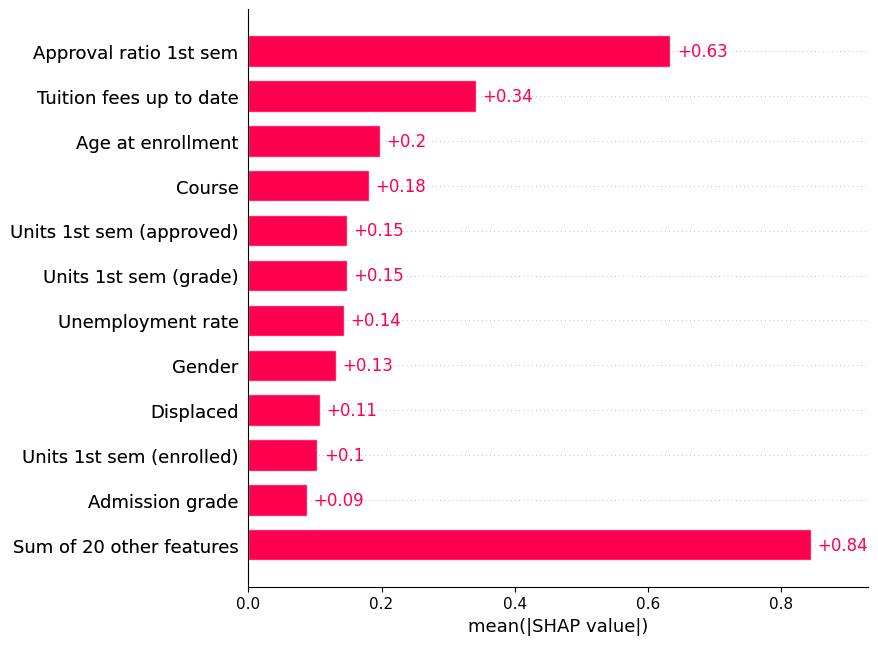

In [7]:
STAGE = "T1"
d = S[STAGE]
ex = explanation(d)

shap.plots.bar(ex, max_display=12)

**Beeswarm.** One dot per student. Dots right of zero raise the Dropout score, and red
dots are students with a high value of the feature. Course, Application mode and the
parents' occupation and qualification are unordered codes, so their colour carries no
meaning.

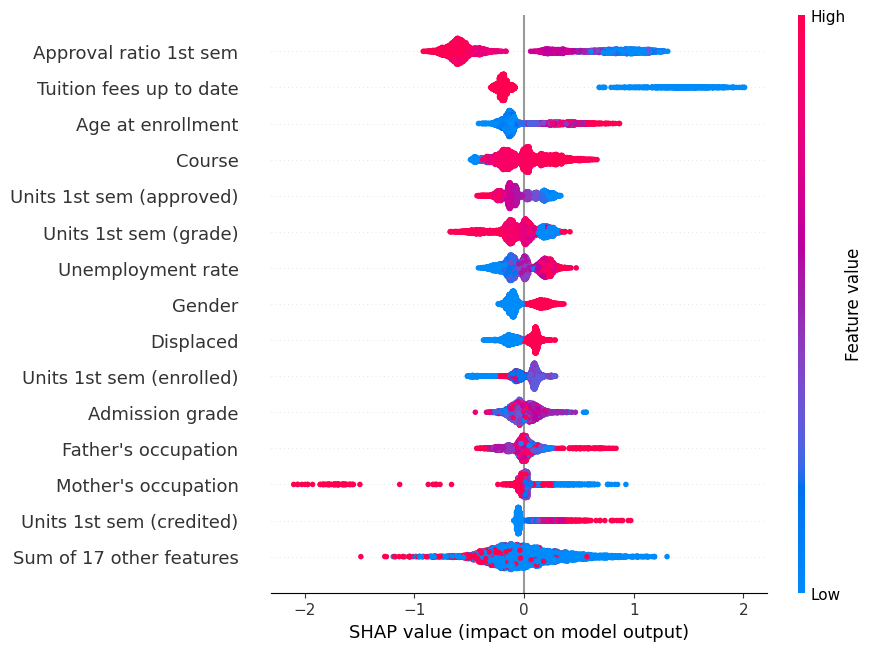

In [8]:
shap.plots.beeswarm(ex, max_display=15)

## 5. Interactions

An interaction value is the part of a prediction that two features produce together.

In [9]:
strength = pair_strength(d["inter"])               # mean |full pair effect|, features x features
pairs = top_pairs(d["X"], strength)

main = np.abs(np.einsum("nii->ni", d["inter"])).mean(0).sum()
off = strength.sum() / 2
print(f"{STAGE}: pairwise interactions make up {off / (main + off):.0%} of mean absolute "
      f"attribution; main effects make up the rest.")
pairs.head(10)

T1: pairwise interactions make up 47% of mean absolute attribution; main effects make up the rest.


,rank,feature_a,feature_b,mean_abs_interaction
0,1,Age at enrollment,Approval ratio 1st sem,0.073334
1,2,GDP,Tuition fees up to date,0.066148
2,3,Tuition fees up to date,Approval ratio 1st sem,0.053752
3,4,Displaced,Approval ratio 1st sem,0.047357
4,5,Course,Approval ratio 1st sem,0.046060
5,6,Admission grade,Approval ratio 1st sem,0.042022
6,7,Curricular units 1st sem (enrolled),Approval ratio 1st sem,0.033944
7,8,Gender,Approval ratio 1st sem,0.033358
8,9,Debtor,Approval ratio 1st sem,0.031038
9,10,Admission grade,GDP,0.028965


The strongest pair is "Age at enrollment x Approval ratio 1st sem". To look at another pair, replace `a, b` with
any two feature names from the table above.

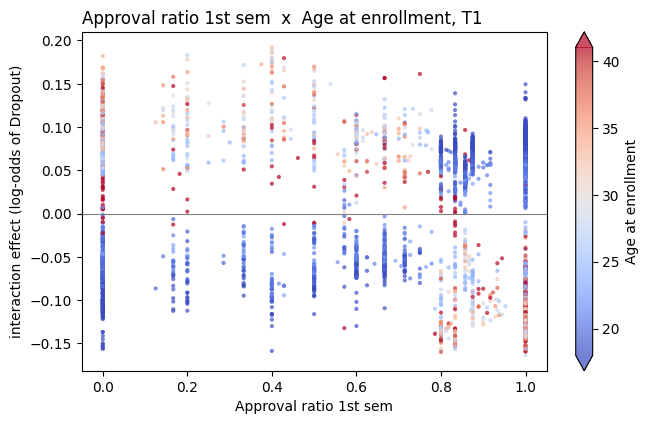

In [10]:
a, b = pairs.loc[0, ["feature_a", "feature_b"]]
fx, fc = sorted([a, b], key=lambda f: d["X"][f].nunique(), reverse=True)   # finer one on x
i, j = d["X"].columns.get_loc(fx), d["X"].columns.get_loc(fc)
effect = d["inter"][:, i, j] + d["inter"][:, j, i]

lo, hi = np.percentile(d["X"][fc], [5, 95])       # colour range without the outliers
if lo == hi:
    lo, hi = d["X"][fc].min(), d["X"][fc].max()

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.axhline(0, color="grey", lw=0.8)
dots = ax.scatter(d["X"][fx], effect, c=d["X"][fc], cmap="coolwarm", vmin=lo, vmax=hi,
                  s=9, alpha=0.7, lw=0)
fig.colorbar(dots, label=short(fc), extend="both")
ax.set_xlabel(short(fx))
ax.set_ylabel("interaction effect (log-odds of Dropout)")
ax.set_title(f"{short(fx)}  x  {short(fc)}, {STAGE}", loc="left")
plt.show()

## 6. One student, stage by stage

A waterfall starts at the base value `E[f(X)]` and adds each feature's SHAP value to reach
the student's Dropout score `f(x)`. Red bars raise the score, blue bars lower it. `ROW` is
the row index in `data/data.csv` (0 = first student).

The final models were fitted on all students, so the probabilities printed here are
in-sample. For honest out-of-fold predictions use `results/<task>/oof_predictions.csv`.

T0: predicted P(Dropout) = 0.15   (actual outcome: Dropout)


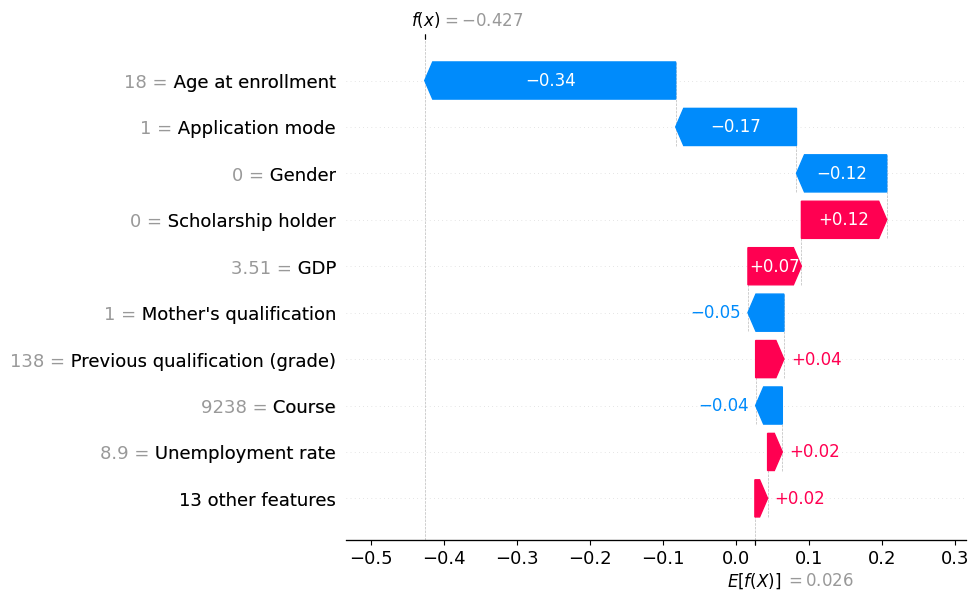

T1: predicted P(Dropout) = 0.66   (actual outcome: Dropout)


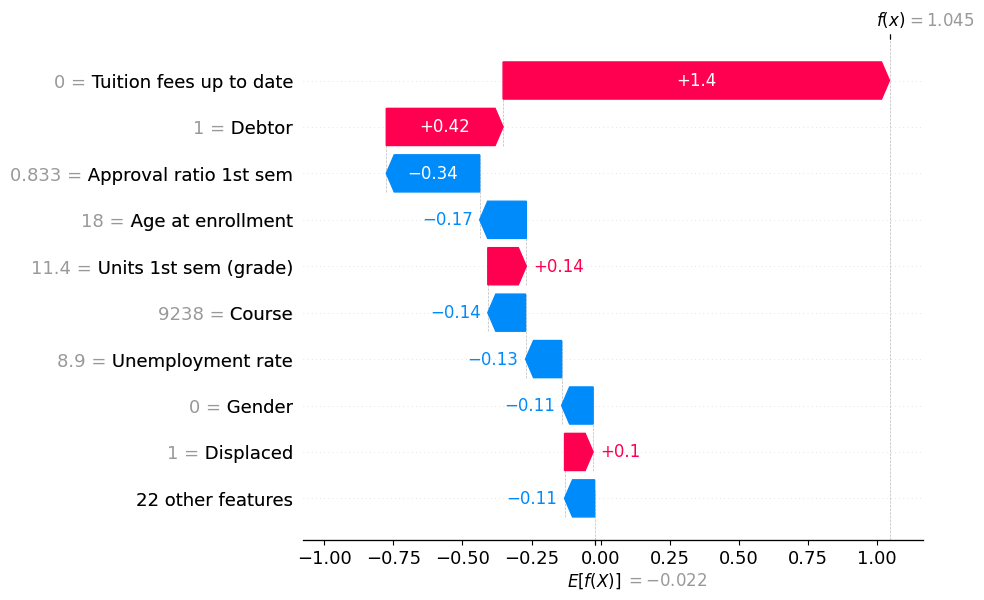

T2: predicted P(Dropout) = 0.83   (actual outcome: Dropout)


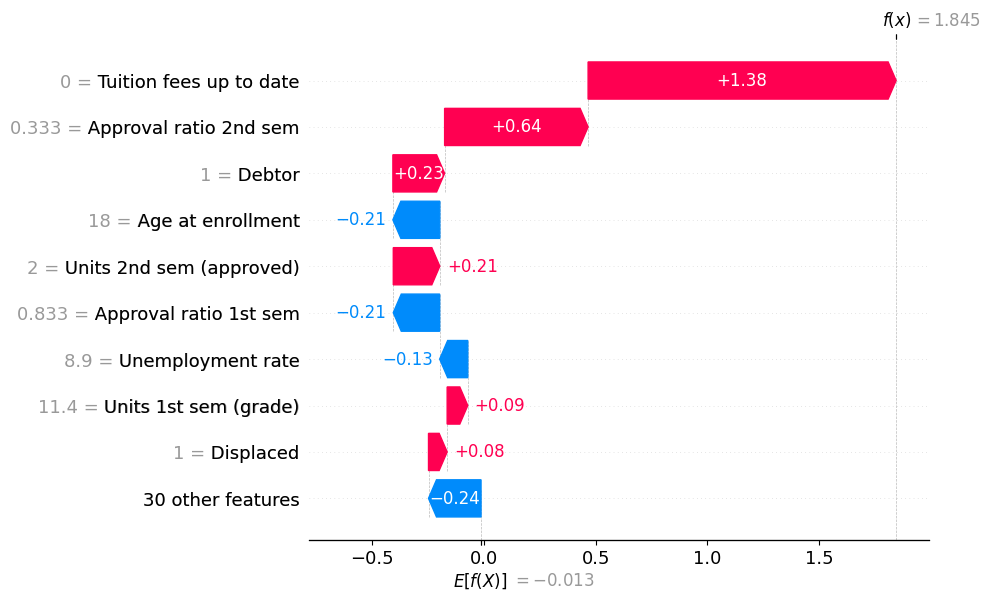

In [11]:
ROW = 9

for stage, d in S.items():
    pos = np.flatnonzero(d["rows"] == ROW)
    if len(pos) == 0:
        raise ValueError(f"Row {ROW} is not in the {TASK} data "
                         "(the binary task excludes Enrolled students).")
    print(f"{stage}: predicted P(Dropout) = {dropout_probability(d)[pos[0]]:.2f}   "
          f"(actual outcome: {df.loc[ROW, C.TARGET]})")
    shap.plots.waterfall(explanation(d)[pos[0]], max_display=10)